# Análise Exploratória dos Dados — Projeto 01

**Unidade Curricular:** Inteligência Artificial  
**Curso:** Engenharia de Sistemas Informáticos  
**Ano Letivo:** 2026/2027  
**Grupo:** G05

---

## Objetivo

Este notebook apresenta a Análise Exploratória dos Dados (EDA) da instância `tiny` fornecida para o Projeto 01.

O objetivo desta análise é compreender e validar os dados antes da modelação e implementação dos algoritmos de Inteligência Artificial.

Em particular, pretende-se:

- compreender a estrutura dos diferentes ficheiros CSV;
- identificar as principais entidades e relações do problema;
- verificar valores em falta, duplicados e chaves inválidas;
- analisar produtores, produtos, clientes e encomendas;
- estudar as janelas temporais de recolha e entrega;
- calcular a procura em termos de peso e compará-la com a capacidade dos veículos;
- analisar as localizações relevantes para as rotas;
- validar a matriz de distâncias e tempos de viagem;
- identificar características dos dados que possam influenciar a futura modelação do problema.

Nesta fase não é realizada qualquer otimização de rotas. A análise serve de base para a representação posterior do problema e para a implementação dos algoritmos de pesquisa.

## 1. Preparação do Ambiente

Nesta primeira etapa são importadas as bibliotecas utilizadas na análise e definida a localização dos ficheiros de dados.

A utilização de um caminho relativo permite que o projeto possa ser executado noutro computador desde que seja preservada a estrutura de diretórios do repositório.

In [64]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

DATA_DIR = Path("data/tiny")

print("Diretório dos dados:", DATA_DIR)
print("Diretório existente:", DATA_DIR.exists())

Diretório dos dados: data/tiny
Diretório existente: True


### 1.1 Ficheiros disponíveis

Antes de carregar os dados, é efetuada uma verificação dos ficheiros CSV existentes na pasta da instância `tiny`.

Esta etapa permite confirmar que todos os ficheiros necessários se encontram disponíveis antes de iniciar a análise.

In [65]:
csv_files = sorted(DATA_DIR.glob("*.csv"))

print(f"Número de ficheiros CSV encontrados: {len(csv_files)}\n")

for file in csv_files:
    print(file.name)

Número de ficheiros CSV encontrados: 11

collection_centers.csv
customers.csv
delivery_locations.csv
distance_matrix.csv
localities.csv
locations.csv
order_items.csv
orders.csv
producers.csv
products.csv
vehicles.csv


### 1.2 Carregamento dos dados

Os onze ficheiros CSV são carregados para `DataFrames` do Pandas.

Cada tabela representa uma entidade ou relação específica do problema, como produtores, produtos, clientes, encomendas, veículos ou localizações.

In [66]:
customers = pd.read_csv(DATA_DIR / "customers.csv")
vehicles = pd.read_csv(DATA_DIR / "vehicles.csv")
localities = pd.read_csv(DATA_DIR / "localities.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
delivery_locations = pd.read_csv(DATA_DIR / "delivery_locations.csv")
orders = pd.read_csv(DATA_DIR / "orders.csv")
locations = pd.read_csv(DATA_DIR / "locations.csv")
order_items = pd.read_csv(DATA_DIR / "order_items.csv")
producers = pd.read_csv(DATA_DIR / "producers.csv")
distance_matrix = pd.read_csv(DATA_DIR / "distance_matrix.csv")
collection_centers = pd.read_csv(DATA_DIR / "collection_centers.csv")

datasets = {
    "Customers": customers,
    "Vehicles": vehicles,
    "Localities": localities,
    "Products": products,
    "Delivery Locations": delivery_locations,
    "Orders": orders,
    "Locations": locations,
    "Order Items": order_items,
    "Producers": producers,
    "Distance Matrix": distance_matrix,
    "Collection Centers": collection_centers
}

print("Datasets carregados com sucesso.")

Datasets carregados com sucesso.


### 1.3 Conversão dos atributos temporais

As colunas que representam datas e horas são convertidas para o tipo `datetime`.

Esta conversão é necessária para calcular durações, comparar instantes e verificar posteriormente o cumprimento das janelas temporais.

In [67]:
orders["order_datetime"] = pd.to_datetime(
    orders["order_datetime"]
)

datetime_columns = [
    "availability_start",
    "availability_end",
    "delivery_start",
    "delivery_end"
]

for column in datetime_columns:
    order_items[column] = pd.to_datetime(
        order_items[column]
    )

print("Colunas temporais convertidas com sucesso.")

Colunas temporais convertidas com sucesso.


## 2. Visão Geral do Dataset

Nesta secção é analisada a dimensão de cada tabela, permitindo obter uma primeira visão da estrutura e da dimensão da instância `tiny`.

Em vez de apresentar integralmente todos os `DataFrames`, é construída uma tabela-resumo com o número de linhas e colunas de cada dataset.

In [68]:
overview = []

for name, df in datasets.items():
    overview.append({
        "Dataset": name,
        "Linhas": df.shape[0],
        "Colunas": df.shape[1]
    })

overview_df = pd.DataFrame(overview)

display(overview_df)

,Dataset,Linhas,Colunas
0,Customers,8,5
1,Vehicles,2,6
2,Localities,49,6
3,Products,23,6
4,Delivery Locations,6,5
5,Orders,10,5
6,Locations,12,7
7,Order Items,23,8
8,Producers,5,6
9,Distance Matrix,132,6


### 2.1 Síntese inicial

A instância `tiny` é constituída por onze tabelas relacionadas entre si.

Entre as entidades principais encontram-se:

- **5 produtores**;
- **23 produtos**;
- **8 clientes**;
- **10 encomendas**;
- **23 itens de encomenda**;
- **1 centro de recolha**;
- **2 veículos**;
- **12 localizações utilizadas na rede de roteamento**.

A tabela `localities` contém 49 localidades, funcionando como informação geográfica de suporte às diferentes entidades.

A `distance_matrix` contém 132 registos, correspondentes às deslocações consideradas entre as localizações utilizadas no problema.

A dimensão reduzida desta instância torna-a adequada para compreender, testar e validar a futura representação do problema antes da aplicação dos métodos à instância de maior dimensão.

### 2.2 Estrutura das tabelas

Para compreender o papel de cada dataset são analisados os nomes das colunas e os respetivos tipos de dados.

Esta informação permite identificar chaves, atributos numéricos, campos temporais e relações entre entidades.

In [69]:
for name, df in datasets.items():
    print("=" * 70)
    print(name)
    print("=" * 70)

    structure = pd.DataFrame({
        "Coluna": df.columns,
        "Tipo": df.dtypes.astype(str).values
    })

    display(structure)

Customers


,Coluna,Tipo
0,customer_id,int64
1,name,str
2,locality_id,int64
3,phone,str
4,email,str


Vehicles


,Coluna,Tipo
0,vehicle_id,int64
1,plate,str
2,center_id,int64
3,capacity_kg,float64
4,refrigerated,int64
5,avg_speed_kmh,float64


Localities


,Coluna,Tipo
0,locality_id,int64
1,name,str
2,municipality,str
3,district,str
4,latitude,float64
5,longitude,float64


... (12 outputs left out)

Distance Matrix


,Coluna,Tipo
0,origin_location_id,int64
1,origin_type,str
2,destination_location_id,int64
3,destination_type,str
4,distance_km,float64
5,duration_min,float64


Collection Centers


,Coluna,Tipo
0,center_id,int64
1,name,str
2,locality_id,int64
3,address,str
4,capacity_kg,float64


## 3. Qualidade e Integridade dos Dados

Antes de analisar o conteúdo dos dados é necessário verificar a sua qualidade.

Nesta secção são avaliados:

- valores em falta;
- linhas duplicadas;
- unicidade das principais chaves;
- consistência das relações entre as diferentes tabelas.

Estas verificações são importantes porque erros nesta fase poderiam originar pedidos incompletos ou rotas incorretamente construídas nas fases seguintes.

In [70]:
quality_summary = []

for name, df in datasets.items():
    quality_summary.append({
        "Dataset": name,
        "Valores em falta": int(df.isna().sum().sum()),
        "Linhas duplicadas": int(df.duplicated().sum())
    })

quality_df = pd.DataFrame(quality_summary)

display(quality_df)

,Dataset,Valores em falta,Linhas duplicadas
0,Customers,0,0
1,Vehicles,0,0
2,Localities,0,0
3,Products,0,0
4,Delivery Locations,0,0
5,Orders,0,0
6,Locations,0,0
7,Order Items,0,0
8,Producers,0,0
9,Distance Matrix,0,0


### 3.1 Valores em falta e duplicados

Não foram identificados valores em falta nem linhas integralmente duplicadas nos datasets analisados.

Este resultado indica que, numa primeira análise, os ficheiros apresentam boa completude estrutural.

No entanto, a inexistência de valores em falta ou duplicados não é suficiente para garantir a integridade dos dados. É também necessário validar as chaves e as relações entre as diferentes entidades.

### 3.2 Validação das chaves primárias

As principais tabelas possuem identificadores que deverão distinguir univocamente cada registo.

É verificado se estas chaves contêm valores duplicados ou em falta.

In [71]:
primary_keys = {
    "Customers": (customers, "customer_id"),
    "Vehicles": (vehicles, "vehicle_id"),
    "Localities": (localities, "locality_id"),
    "Products": (products, "product_id"),
    "Delivery Locations": (
        delivery_locations,
        "delivery_location_id"
    ),
    "Orders": (orders, "order_id"),
    "Locations": (locations, "location_id"),
    "Order Items": (order_items, "order_item_id"),
    "Producers": (producers, "producer_id"),
    "Collection Centers": (
        collection_centers,
        "center_id"
    )
}

pk_results = []

for name, (df, key) in primary_keys.items():
    pk_results.append({
        "Dataset": name,
        "Chave primária": key,
        "Valores únicos": df[key].is_unique,
        "Valores em falta": int(df[key].isna().sum())
    })

pk_results_df = pd.DataFrame(pk_results)

display(pk_results_df)

,Dataset,Chave primária,Valores únicos,Valores em falta
0,Customers,customer_id,True,0
1,Vehicles,vehicle_id,True,0
2,Localities,locality_id,True,0
3,Products,product_id,True,0
4,Delivery Locations,delivery_location_id,True,0
5,Orders,order_id,True,0
6,Locations,location_id,True,0
7,Order Items,order_item_id,True,0
8,Producers,producer_id,True,0
9,Collection Centers,center_id,True,0


Todas as chaves primárias analisadas são únicas e não apresentam valores em falta.

Desta forma, cada entidade pode ser identificada de forma inequívoca através do respetivo identificador.

### 3.3 Integridade referencial

Grande parte da informação necessária ao problema encontra-se distribuída por diferentes tabelas.

Por exemplo, um item de encomenda referencia um produto e uma encomenda; o produto referencia um produtor; e a encomenda referencia um cliente e um local de entrega.

É por isso necessário confirmar que todas estas referências correspondem a registos existentes.

In [72]:
foreign_keys = [
    (
        "producers.locality_id → localities.locality_id",
        producers["locality_id"],
        localities["locality_id"]
    ),
    (
        "customers.locality_id → localities.locality_id",
        customers["locality_id"],
        localities["locality_id"]
    ),
    (
        "delivery_locations.locality_id → localities.locality_id",
        delivery_locations["locality_id"],
        localities["locality_id"]
    ),
    (
        "collection_centers.locality_id → localities.locality_id",
        collection_centers["locality_id"],
        localities["locality_id"]
    ),
    (
        "vehicles.center_id → collection_centers.center_id",
        vehicles["center_id"],
        collection_centers["center_id"]
    ),
    (
        "products.producer_id → producers.producer_id",
        products["producer_id"],
        producers["producer_id"]
    ),
    (
        "orders.customer_id → customers.customer_id",
        orders["customer_id"],
        customers["customer_id"]
    ),
    (
        "orders.delivery_location_id → delivery_locations.delivery_location_id",
        orders["delivery_location_id"],
        delivery_locations["delivery_location_id"]
    ),
    (
        "order_items.order_id → orders.order_id",
        order_items["order_id"],
        orders["order_id"]
    ),
    (
        "order_items.product_id → products.product_id",
        order_items["product_id"],
        products["product_id"]
    )
]

fk_results = []

for relationship, source, target in foreign_keys:
    invalid_references = set(source) - set(target)

    fk_results.append({
        "Relação": relationship,
        "Referências inválidas": len(invalid_references)
    })

fk_results_df = pd.DataFrame(fk_results)

display(fk_results_df)

,Relação,Referências inválidas
0,producers.locality_id → localities.locality_id,0
1,customers.locality_id → localities.locality_id,0
2,delivery_locations.locality_id → localities.lo...,0
3,collection_centers.locality_id → localities.lo...,0
4,vehicles.center_id → collection_centers.center_id,0
5,products.producer_id → producers.producer_id,0
6,orders.customer_id → customers.customer_id,0
7,orders.delivery_location_id → delivery_locatio...,0
8,order_items.order_id → orders.order_id,0
9,order_items.product_id → products.product_id,0


Não foram identificadas referências inválidas nas principais relações entre os datasets.

Assim, todos os produtos estão associados a produtores existentes, todos os itens pertencem a encomendas e produtos válidos e as restantes relações fundamentais entre as entidades encontram-se consistentes.

Esta validação é especialmente importante para a fase de modelação, uma vez que a representação de cada pedido exigirá combinar informação proveniente de várias tabelas.

### 3.4 Consistência da tabela de localizações

A tabela `locations` funciona como uma representação unificada dos pontos que podem ser utilizados nas rotas.

O campo `ref_id` identifica a entidade concreta associada a cada localização, dependendo do seu tipo:

- `producer` → referência a `producer_id`;
- `collection_center` → referência a `center_id`;
- `delivery_location` → referência a `delivery_location_id`.

É por isso importante confirmar que todas estas referências correspondem a entidades existentes.

In [73]:
location_reference_checks = []

reference_rules = [
    (
        "producer",
        producers["producer_id"]
    ),
    (
        "collection_center",
        collection_centers["center_id"]
    ),
    (
        "delivery_location",
        delivery_locations["delivery_location_id"]
    )
]

for location_type, valid_ids in reference_rules:

    refs = locations.loc[
        locations["location_type"] == location_type,
        "ref_id"
    ]

    invalid = set(refs) - set(valid_ids)

    location_reference_checks.append({
        "Tipo de localização": location_type,
        "Número de localizações": len(refs),
        "Referências inválidas": len(invalid)
    })

location_reference_df = pd.DataFrame(
    location_reference_checks
)

display(location_reference_df)

,Tipo de localização,Número de localizações,Referências inválidas
0,producer,5,0
1,collection_center,1,0
2,delivery_location,6,0


Todas as referências existentes na tabela `locations` correspondem a entidades válidas.

Assim, cada localização classificada como produtor, centro de recolha ou local de entrega pode ser corretamente associada ao respetivo registo de origem.

Com estas verificações concluídas, considera-se que a estrutura relacional da instância `tiny` é suficientemente consistente para prosseguir com a análise do seu conteúdo.

## 4. Análise das Entidades e da Procura

Depois de validada a estrutura dos dados, são analisadas as entidades com maior relevância para o problema de distribuição.

O objetivo desta secção é perceber:

- como os produtos se encontram distribuídos pelos produtores;
- quais as categorias existentes;
- como são constituídas as encomendas;
- quantos itens existem em cada encomenda;
- quais os produtores mais representados nos pedidos.

Nesta análise são privilegiadas estatísticas agregadas, evitando apresentar informação pessoal dos clientes que não tem relevância para o problema de roteamento.

### 4.1 Produtores

Os produtores correspondem aos pontos onde os veículos terão de realizar operações de recolha.

Nesta primeira análise é estudado o número de produtos disponibilizados por cada produtor e a respetiva localização geográfica.

In [74]:
products_per_producer = (
    products
    .groupby("producer_id")
    .size()
    .rename("number_of_products")
    .reset_index()
)

producer_overview = (
    producers[
        [
            "producer_id",
            "name",
            "locality_id"
        ]
    ]
    .merge(
        localities[
            [
                "locality_id",
                "municipality",
                "district"
            ]
        ],
        on="locality_id",
        how="left"
    )
    .merge(
        products_per_producer,
        on="producer_id",
        how="left"
    )
)

display(producer_overview)

,producer_id,name,locality_id,municipality,district,number_of_products
0,1,Hortas Valente,23,Fafe,Braga,5
1,2,Quinta Leite,39,Vieira do Minho,Braga,4
2,3,Quinta Morais,12,Guimaraes,Braga,7
3,4,Pomar Carvalho,49,Povoa de Varzim,Porto,4
4,5,Pomar Antunes,23,Fafe,Braga,3


A instância contém **5 produtores**, todos com produtos disponíveis.

A quantidade de produtos disponibilizados não é uniforme. O produtor com maior variedade disponibiliza 7 produtos, enquanto o produtor com menor variedade disponibiliza 3.

Esta distribuição é relevante para caracterizar o dataset, embora o número de produtos disponíveis por produtor não determine, por si só, a frequência com que cada produtor será visitado. Essa frequência dependerá dos produtos efetivamente incluídos nas encomendas.

### 4.2 Produtos

Os produtos determinam o produtor que deverá ser visitado durante uma operação de recolha.

São analisadas as categorias existentes e as unidades utilizadas para representar as quantidades pedidas.

In [75]:
category_summary = (
    products["category"]
    .value_counts()
    .rename_axis("Categoria")
    .reset_index(name="Número de produtos")
)

display(category_summary)

,Categoria,Número de produtos
0,vegetable,12
1,fruit,9
2,other,2


In [76]:
unit_summary = (
    products["unit"]
    .value_counts()
    .rename_axis("Unidade")
    .reset_index(name="Número de produtos")
)

display(unit_summary)

,Unidade,Número de produtos
0,kg,17
1,unit,6


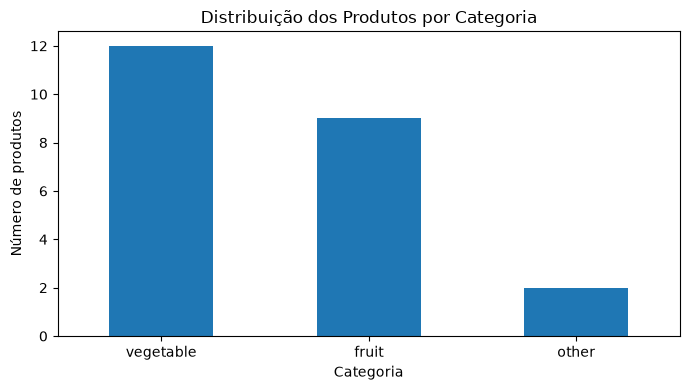

In [77]:
products["category"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Distribuição dos Produtos por Categoria"
)

plt.xlabel("Categoria")
plt.ylabel("Número de produtos")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

O catálogo contém **23 produtos**.

A categoria mais representada é `vegetable`, com 12 produtos, seguida de `fruit`, com 9, e `other`, com 2.

Relativamente à unidade de medida, 17 produtos são representados em quilogramas e 6 através de unidades individuais.

A existência de diferentes unidades não cria um problema para a análise da capacidade dos veículos, uma vez que o dataset disponibiliza também `unit_weight_kg`, permitindo converter as quantidades pedidas para um peso estimado em quilogramas.

### 4.3 Clientes e Encomendas

Os clientes originam a procura do sistema através das encomendas realizadas.

Para o problema de roteamento, os atributos mais relevantes das encomendas são o cliente associado, o local de entrega e os respetivos itens.

Informação pessoal, como telefone ou endereço de email, não é necessária para a construção das rotas e não é utilizada nesta análise.

In [78]:
orders_summary = pd.DataFrame({
    "Indicador": [
        "Número de clientes",
        "Clientes com pelo menos uma encomenda",
        "Número de encomendas",
        "Número de itens de encomenda",
        "Locais de entrega utilizados"
    ],
    "Valor": [
        len(customers),
        orders["customer_id"].nunique(),
        len(orders),
        len(order_items),
        orders["delivery_location_id"].nunique()
    ]
})

display(orders_summary)

,Indicador,Valor
0,Número de clientes,8
1,Clientes com pelo menos uma encomenda,7
2,Número de encomendas,10
3,Número de itens de encomenda,23
4,Locais de entrega utilizados,6


In [79]:
order_status_summary = (
    orders["status"]
    .value_counts()
    .rename_axis("Estado")
    .reset_index(name="Número de encomendas")
)

display(order_status_summary)

,Estado,Número de encomendas
0,placed,5
1,confirmed,4
2,delivered,1


O dataset contém 10 encomendas realizadas por 7 dos 8 clientes existentes.

As encomendas apresentam três estados distintos:

- 5 encontram-se em estado `placed`;
- 4 em estado `confirmed`;
- 1 em estado `delivered`.

Nesta fase, o campo `status` é tratado apenas como informação descritiva. O enunciado do projeto não estabelece uma regra de roteamento baseada neste atributo, pelo que não serão excluídas encomendas com base no seu estado sem uma indicação adicional.

### 4.4 Itens por Encomenda

Uma encomenda pode ser constituída por vários produtos e, consequentemente, originar várias operações de recolha.

É analisado o número de itens associado a cada encomenda.

In [80]:
items_per_order = (
    order_items
    .groupby("order_id")
    .size()
    .rename("number_of_items")
)

display(
    items_per_order
    .describe()
    .to_frame(name="Itens por encomenda")
)

,Itens por encomenda
count,10.00000
mean,2.30000
std,1.05935
min,1.00000
25%,1.25000
50%,2.50000
75%,3.00000
max,4.00000


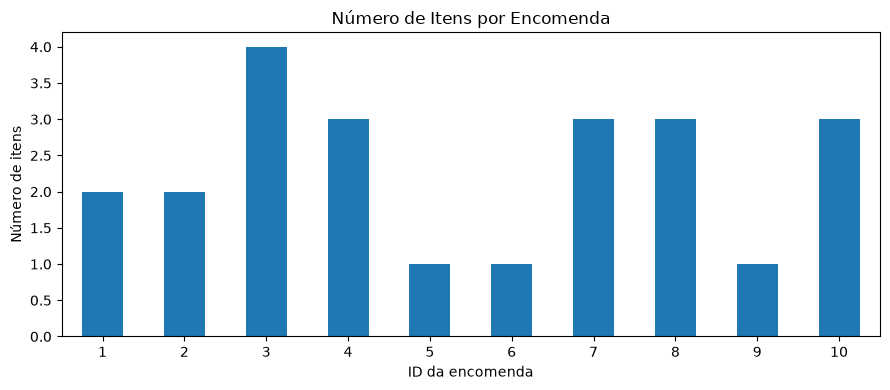

In [81]:
items_per_order.plot(
    kind="bar",
    figsize=(9, 4),
    title="Número de Itens por Encomenda"
)

plt.xlabel("ID da encomenda")
plt.ylabel("Número de itens")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

As 10 encomendas contêm um total de 23 itens, correspondendo a uma média de **2,3 itens por encomenda**.

O número de itens varia entre 1 e 4.

Este aspeto é importante para o problema de roteamento porque uma única encomenda pode requerer recolhas em vários produtores antes de todos os produtos associados poderem ser entregues no local escolhido pelo cliente.

### 4.5 Produtores Envolvidos nos Pedidos

A quantidade de produtos existente no catálogo de um produtor não corresponde necessariamente à procura que esse produtor gera.

Para avaliar essa procura, os itens das encomendas são associados aos respetivos produtos e produtores.

In [82]:
item_producers = (
    order_items
    .merge(
        products[
            [
                "product_id",
                "producer_id"
            ]
        ],
        on="product_id",
        how="left"
    )
)

items_by_producer = (
    item_producers
    .groupby("producer_id")
    .size()
    .rename("number_of_order_items")
    .reset_index()
    .merge(
        producers[
            [
                "producer_id",
                "name"
            ]
        ],
        on="producer_id",
        how="left"
    )
    .sort_values(
        "number_of_order_items",
        ascending=False
    )
)

display(items_by_producer)

,producer_id,number_of_order_items,name
2,3,7,Quinta Morais
3,4,7,Pomar Carvalho
0,1,5,Hortas Valente
1,2,3,Quinta Leite
4,5,1,Pomar Antunes


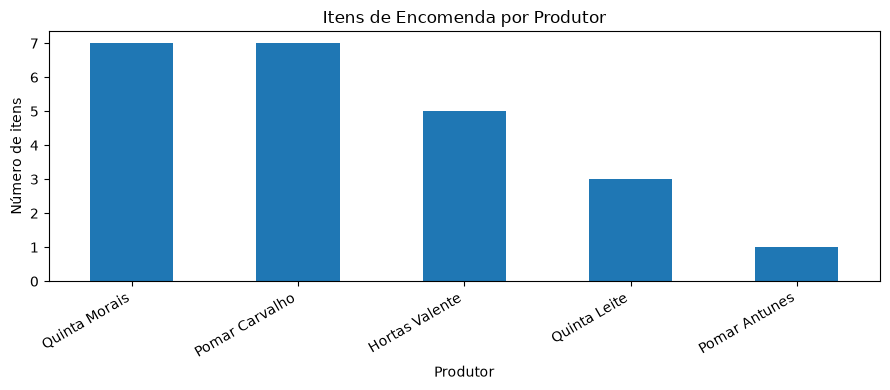

In [83]:
(
    items_by_producer
    .set_index("name")["number_of_order_items"]
    .plot(
        kind="bar",
        figsize=(9, 4),
        title="Itens de Encomenda por Produtor"
    )
)

plt.xlabel("Produtor")
plt.ylabel("Número de itens")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Todos os cinco produtores aparecem em pelo menos um item de encomenda, mas a procura encontra-se distribuída de forma desigual.

A `Quinta Morais` e o `Pomar Carvalho` estão associados ao maior número de itens, com 7 cada, enquanto o `Pomar Antunes` aparece apenas num item.

Esta diferença poderá influenciar as rotas construídas, uma vez que determinados produtores terão de ser considerados com maior frequência durante o planeamento das recolhas.

## 5. Análise Temporal

As janelas temporais constituem uma das principais restrições do problema.

Cada item de encomenda contém duas janelas distintas:

- `availability_start` e `availability_end`, que definem quando o produto pode ser recolhido no produtor;
- `delivery_start` e `delivery_end`, que definem o intervalo associado à entrega.

Uma rota geograficamente curta poderá ser inválida se não respeitar estes intervalos. Por esse motivo, a qualidade e as características das janelas temporais são analisadas antes da modelação do agente.

### 5.1 Validade das Janelas Temporais

Começa-se por verificar se existem intervalos temporalmente impossíveis, isto é, situações em que o início de uma janela ocorre depois do seu fim.

In [84]:
invalid_availability = order_items[
    order_items["availability_start"]
    >
    order_items["availability_end"]
]

invalid_delivery = order_items[
    order_items["delivery_start"]
    >
    order_items["delivery_end"]
]

window_validation = pd.DataFrame({
    "Verificação": [
        "Janelas de recolha inválidas",
        "Janelas de entrega inválidas"
    ],
    "Número de casos": [
        len(invalid_availability),
        len(invalid_delivery)
    ]
})

display(window_validation)

,Verificação,Número de casos
0,Janelas de recolha inválidas,0
1,Janelas de entrega inválidas,0


Não foram identificadas janelas temporais em que o instante inicial seja posterior ao instante final.

Assim, todas as janelas possuem uma estrutura temporal válida.

In [85]:
order_items["availability_window_hours"] = (
    order_items["availability_end"]
    -
    order_items["availability_start"]
).dt.total_seconds() / 3600

order_items["delivery_window_hours"] = (
    order_items["delivery_end"]
    -
    order_items["delivery_start"]
).dt.total_seconds() / 3600

window_stats = order_items[
    [
        "availability_window_hours",
        "delivery_window_hours"
    ]
].describe()

display(window_stats)

,availability_window_hours,delivery_window_hours
count,23.000000,23.000000
mean,3.869565,2.782609
std,1.455533,1.126399
min,2.000000,1.000000
25%,3.000000,2.000000
50%,4.000000,3.000000
75%,5.000000,4.000000
max,6.000000,4.000000


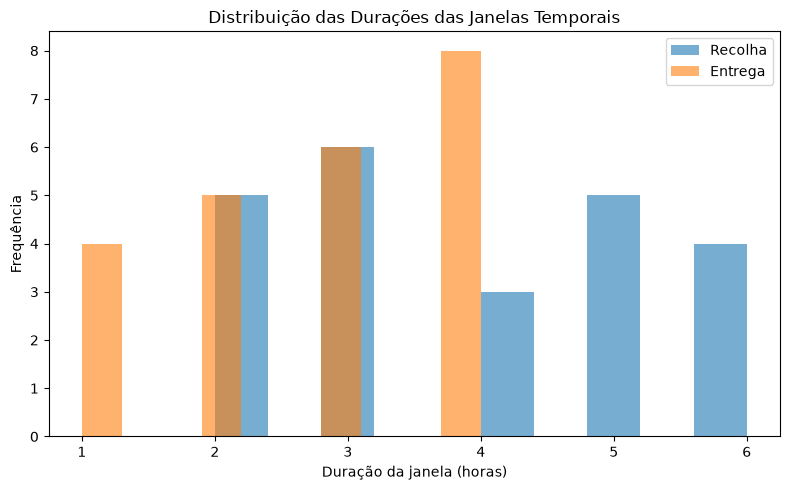

In [86]:
plt.figure(figsize=(8, 5))

plt.hist(
    order_items["availability_window_hours"],
    alpha=0.6,
    label="Recolha"
)

plt.hist(
    order_items["delivery_window_hours"],
    alpha=0.6,
    label="Entrega"
)

plt.xlabel("Duração da janela (horas)")
plt.ylabel("Frequência")
plt.title("Distribuição das Durações das Janelas Temporais")
plt.legend()
plt.tight_layout()
plt.show()

As janelas de recolha apresentam uma duração média de aproximadamente **3,87 horas**, enquanto as janelas de entrega apresentam uma duração média de aproximadamente **2,78 horas**.

As janelas de entrega são, portanto, em média, mais restritas do que as janelas de recolha.

Este resultado sugere que os limites de entrega poderão ter um papel particularmente importante durante a construção das rotas, uma vez que deixam menor margem temporal ao agente.

In [87]:
different_days = order_items[
    order_items["availability_start"].dt.date
    !=
    order_items["delivery_start"].dt.date
].copy()

print(
    "Itens com recolha e entrega em dias diferentes:",
    len(different_days)
)

Itens com recolha e entrega em dias diferentes: 6


In [88]:
display(
    different_days[
        [
            "order_item_id",
            "order_id",
            "availability_start",
            "availability_end",
            "delivery_start",
            "delivery_end"
        ]
    ]
)

,order_item_id,order_id,availability_start,availability_end,delivery_start,delivery_end
1,2,1,2026-10-17 12:45:00,2026-10-17 15:45:00,2026-10-18 13:45:00,2026-10-18 17:45:00
10,11,4,2026-10-20 08:30:00,2026-10-20 10:30:00,2026-10-21 13:30:00,2026-10-21 17:30:00
12,13,6,2026-10-09 12:15:00,2026-10-09 15:15:00,2026-10-10 13:15:00,2026-10-10 17:15:00
15,16,7,2026-10-08 09:15:00,2026-10-08 15:15:00,2026-10-09 13:15:00,2026-10-09 16:15:00
16,17,8,2026-10-19 10:00:00,2026-10-19 16:00:00,2026-10-20 13:00:00,2026-10-20 15:00:00
17,18,8,2026-10-07 09:15:00,2026-10-07 13:15:00,2026-10-08 12:15:00,2026-10-08 14:15:00


Foram identificados **6 itens de encomenda cuja janela de recolha e a janela de entrega começam em dias diferentes**.

Este aspeto é relevante para a modelação, uma vez que o estado temporal do agente não pode assumir que todas as operações relativas a um pedido serão concluídas no mesmo dia.

### 5.2 Relação com `order_datetime`

Para além das janelas dos itens, a tabela `orders` contém o campo `order_datetime`.

É analisada a relação entre este atributo e os instantes definidos nas janelas de recolha e entrega, procurando identificar eventuais particularidades do dataset sintético.

In [89]:
temporal_consistency = (
    order_items
    .merge(
        orders[
            [
                "order_id",
                "order_datetime"
            ]
        ],
        on="order_id",
        how="left"
    )
)

temporal_checks = pd.DataFrame({
    "Verificação": [
        "availability_start anterior a order_datetime",
        "availability_end anterior a order_datetime",
        "delivery_start anterior a order_datetime",
        "delivery_end anterior a order_datetime"
    ],
    "Número de itens": [
        (
            temporal_consistency["availability_start"]
            <
            temporal_consistency["order_datetime"]
        ).sum(),

        (
            temporal_consistency["availability_end"]
            <
            temporal_consistency["order_datetime"]
        ).sum(),

        (
            temporal_consistency["delivery_start"]
            <
            temporal_consistency["order_datetime"]
        ).sum(),

        (
            temporal_consistency["delivery_end"]
            <
            temporal_consistency["order_datetime"]
        ).sum()
    ]
})

display(temporal_checks)

,Verificação,Número de itens
0,availability_start anterior a order_datetime,13
1,availability_end anterior a order_datetime,12
2,delivery_start anterior a order_datetime,11
3,delivery_end anterior a order_datetime,11


### Observação sobre `order_datetime`

Foi identificada uma particularidade temporal no dataset: existem itens cujas janelas de disponibilidade ou entrega ocorrem antes do `order_datetime` associado à respetiva encomenda.

Por se tratar de um dataset sintético, este resultado não será automaticamente interpretado como um erro.

O enunciado do projeto identifica explicitamente `availability_start`, `availability_end`, `delivery_start` e `delivery_end` como informação necessária para o problema de roteamento. Por esse motivo, nesta fase, estas quatro variáveis serão consideradas as principais restrições temporais.

O atributo `order_datetime` será mantido como informação descritiva da encomenda, mas não será utilizado como restrição operacional enquanto não existir uma indicação adicional sobre o seu significado no modelo.

Esta decisão deverá ser revista caso sejam fornecidos novos esclarecimentos sobre o dataset.

### 5.3 Síntese da Análise Temporal

A análise permite retirar três conclusões principais:

1. todas as janelas possuem início e fim temporalmente válidos;
2. as janelas de entrega são, em média, mais curtas do que as janelas de recolha;
3. existem pedidos que envolvem mais do que um dia e particularidades na relação entre `order_datetime` e as respetivas janelas.

Por estes motivos, a dimensão temporal deverá ser explicitamente representada no estado do futuro agente e atualizada após cada deslocação, recolha, eventual espera e entrega.

## 6. Peso dos Pedidos e Capacidade dos Veículos

A capacidade dos veículos é uma das restrições que deverá ser respeitada durante a construção das rotas.

O dataset fornece a quantidade pedida de cada produto e o respetivo peso unitário, permitindo estimar o peso transportado por cada item através de:

\[
peso_i = quantidade_i \times pesoUnitario_i
\]

A análise seguinte compara a procura do dataset com as capacidades dos veículos disponíveis.

In [90]:
items_weight = (
    order_items
    .merge(
        products[
            [
                "product_id",
                "producer_id",
                "name",
                "category",
                "unit",
                "unit_weight_kg"
            ]
        ],
        on="product_id",
        how="left"
    )
)

items_weight["weight_kg"] = (
    items_weight["quantity"]
    *
    items_weight["unit_weight_kg"]
)

display(
    items_weight[
        [
            "order_item_id",
            "order_id",
            "product_id",
            "name",
            "quantity",
            "unit",
            "unit_weight_kg",
            "weight_kg"
        ]
    ].head(10)
)

,order_item_id,order_id,product_id,name,quantity,unit,unit_weight_kg,weight_kg
0,1,1,1,Batata,14.1,kg,1.0,14.10
1,2,1,8,Uva,17.2,kg,1.0,17.20
2,3,2,7,Couve,11.0,unit,1.2,13.20
3,4,2,9,Castanha,5.1,kg,1.0,5.10
4,5,3,19,Limao,1.4,kg,1.0,1.40
5,6,3,20,Couve,20.5,unit,1.2,24.60
6,7,3,19,Limao,21.1,kg,1.0,21.10
7,8,3,18,Alface,3.0,unit,0.3,0.90
8,9,4,12,Cenoura,4.2,kg,1.0,4.20
9,10,4,18,Alface,21.8,unit,0.3,6.54


### 6.1 Peso por Encomenda

Os pesos dos itens são agregados por encomenda para determinar a dimensão aproximada de cada pedido.

In [91]:
order_weights = (
    items_weight
    .groupby("order_id", as_index=False)
    ["weight_kg"]
    .sum()
    .rename(
        columns={
            "weight_kg": "total_weight_kg"
        }
    )
)

display(order_weights)

,order_id,total_weight_kg
0,1,31.30
1,2,18.30
2,3,48.00
3,4,13.54
4,5,3.20
5,6,22.90
6,7,49.90
7,8,22.58
8,9,2.90
9,10,36.34


In [92]:
weight_summary = pd.DataFrame({
    "Indicador": [
        "Peso total dos itens (kg)",
        "Peso médio por encomenda (kg)",
        "Encomenda mais pesada (kg)",
        "Encomenda mais leve (kg)"
    ],
    "Valor": [
        items_weight["weight_kg"].sum(),
        order_weights["total_weight_kg"].mean(),
        order_weights["total_weight_kg"].max(),
        order_weights["total_weight_kg"].min()
    ]
})

weight_summary["Valor"] = (
    weight_summary["Valor"].round(2)
)

display(weight_summary)

,Indicador,Valor
0,Peso total dos itens (kg),248.96
1,Peso médio por encomenda (kg),24.90
2,Encomenda mais pesada (kg),49.90
3,Encomenda mais leve (kg),2.90


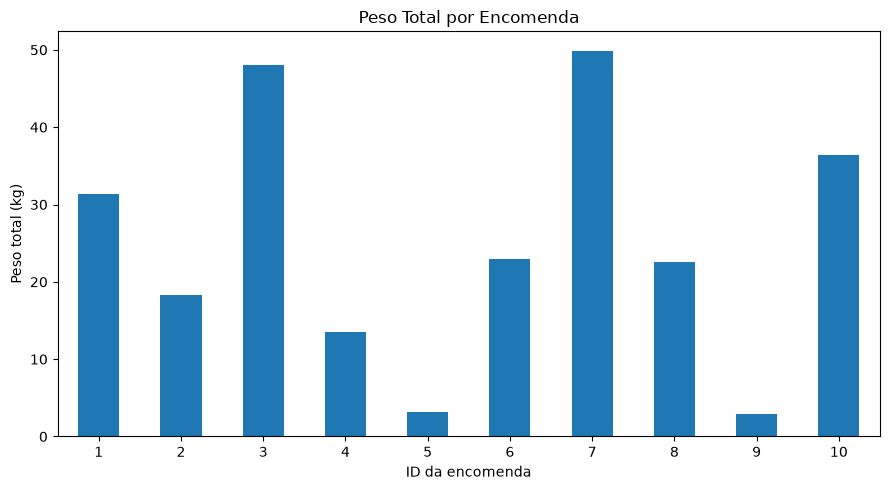

In [93]:
order_weights.plot(
    x="order_id",
    y="total_weight_kg",
    kind="bar",
    figsize=(9, 5),
    legend=False,
    title="Peso Total por Encomenda"
)

plt.xlabel("ID da encomenda")
plt.ylabel("Peso total (kg)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6.2 Capacidade dos Veículos

São analisadas as características dos veículos diretamente relacionadas com a futura modelação.

In [94]:
display(
    vehicles[
        [
            "vehicle_id",
            "center_id",
            "capacity_kg",
            "refrigerated",
            "avg_speed_kmh"
        ]
    ]
)

,vehicle_id,center_id,capacity_kg,refrigerated,avg_speed_kmh
0,1,1,1444.7,0,57.8
1,2,1,1009.8,0,59.5


In [95]:
smallest_vehicle_capacity = (
    vehicles["capacity_kg"].min()
)

largest_order_weight = (
    order_weights["total_weight_kg"].max()
)

total_fleet_capacity = (
    vehicles["capacity_kg"].sum()
)

capacity_summary = pd.DataFrame({
    "Indicador": [
        "Menor capacidade individual (kg)",
        "Maior peso de uma encomenda (kg)",
        "Capacidade nominal total da frota (kg)",
        "Peso total dos itens (kg)"
    ],
    "Valor": [
        smallest_vehicle_capacity,
        largest_order_weight,
        total_fleet_capacity,
        items_weight["weight_kg"].sum()
    ]
})

capacity_summary["Valor"] = (
    capacity_summary["Valor"].round(2)
)

display(capacity_summary)

,Indicador,Valor
0,Menor capacidade individual (kg),1009.80
1,Maior peso de uma encomenda (kg),49.90
2,Capacidade nominal total da frota (kg),2454.50
3,Peso total dos itens (kg),248.96


In [96]:
orders_over_capacity = order_weights[
    order_weights["total_weight_kg"]
    >
    smallest_vehicle_capacity
]

print(
    "Encomendas que ultrapassam individualmente "
    "a capacidade do veículo mais pequeno:",
    len(orders_over_capacity)
)

Encomendas que ultrapassam individualmente a capacidade do veículo mais pequeno: 0


Nenhuma encomenda ultrapassa individualmente a capacidade do veículo com menor capacidade.

Além disso, o conjunto completo dos itens representa aproximadamente **248,96 kg**, valor bastante inferior às capacidades dos veículos disponíveis.

Isto sugere que, na instância `tiny`, a capacidade não deverá ser a restrição dominante.

Contudo, esta conclusão não significa que a capacidade possa ser ignorada. Durante uma rota, o veículo poderá transportar simultaneamente produtos pertencentes a várias encomendas. Assim, a restrição relevante é a **carga do veículo em cada instante**, e não apenas o peso individual de uma encomenda ou o peso total do dataset.

A capacidade deverá, por isso, continuar a ser verificada durante a construção das rotas e será especialmente relevante na instância de maior dimensão.

### 6.3 Procura em Peso por Produtor

Para além do número de itens associado a cada produtor, é útil analisar a quantidade total de peso que deverá ser recolhida em cada origem.

In [97]:
producer_demand = (
    items_weight
    .groupby("producer_id")
    .agg(
        number_of_items=(
            "order_item_id",
            "count"
        ),
        total_weight_kg=(
            "weight_kg",
            "sum"
        )
    )
    .reset_index()
    .merge(
        producers[
            [
                "producer_id",
                "name"
            ]
        ],
        on="producer_id",
        how="left"
    )
    .sort_values(
        "total_weight_kg",
        ascending=False
    )
)

producer_demand["total_weight_kg"] = (
    producer_demand["total_weight_kg"]
    .round(2)
)

display(producer_demand)

,producer_id,number_of_items,total_weight_kg,name
2,3,7,73.70,Quinta Morais
0,1,5,65.40,Hortas Valente
3,4,7,60.36,Pomar Carvalho
1,2,3,35.50,Quinta Leite
4,5,1,14.00,Pomar Antunes


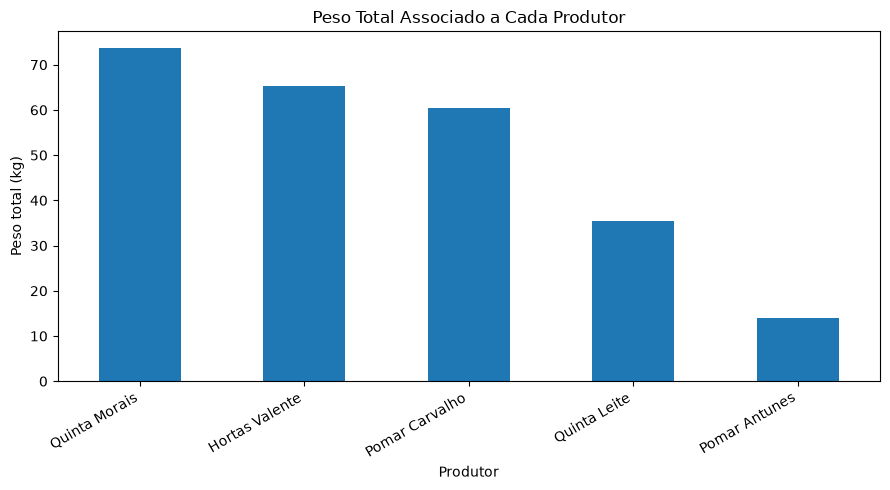

In [98]:
(
    producer_demand
    .set_index("name")["total_weight_kg"]
    .plot(
        kind="bar",
        figsize=(9, 5),
        title="Peso Total Associado a Cada Produtor"
    )
)

plt.xlabel("Produtor")
plt.ylabel("Peso total (kg)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

A procura em peso também não se encontra uniformemente distribuída.

A `Quinta Morais` apresenta o maior peso total associado aos pedidos, com aproximadamente **73,70 kg**, seguida das `Hortas Valente`, com **65,40 kg**, e do `Pomar Carvalho`, com **60,36 kg**.

Estes produtores poderão assumir maior relevância durante a construção das rotas, dado concentrarem uma parte significativa da procura existente na instância.

## 7. Análise Geográfica das Localizações

O agente não necessita de visitar todas as localidades existentes na tabela `localities`.

Para o problema de roteamento, os pontos relevantes encontram-se identificados na tabela `locations`, que reúne produtores, o centro de recolha e os locais de entrega.

Nesta secção é analisada a composição e distribuição geográfica dessa rede.

In [99]:
location_type_summary = (
    locations["location_type"]
    .value_counts()
    .rename_axis("Tipo")
    .reset_index(name="Número de localizações")
)

display(location_type_summary)

,Tipo,Número de localizações
0,delivery_location,6
1,producer,5
2,collection_center,1


A rede de roteamento contém **12 localizações**:

- 5 produtores;
- 1 centro de recolha;
- 6 locais de entrega.

Estes são os pontos que poderão aparecer nas rotas dos veículos.

In [100]:
district_summary = (
    localities["district"]
    .value_counts()
    .rename_axis("Distrito")
    .reset_index(name="Número de localidades")
)

display(district_summary)

,Distrito,Número de localidades
0,Braga,45
1,Porto,4


A tabela de localidades é predominantemente composta por localidades do distrito de Braga, contendo também registos do distrito do Porto.

Esta tabela funciona como suporte geográfico das diferentes entidades. Para o cálculo efetivo das rotas será utilizada a tabela `locations`, que contém apenas os pontos operacionais relevantes.

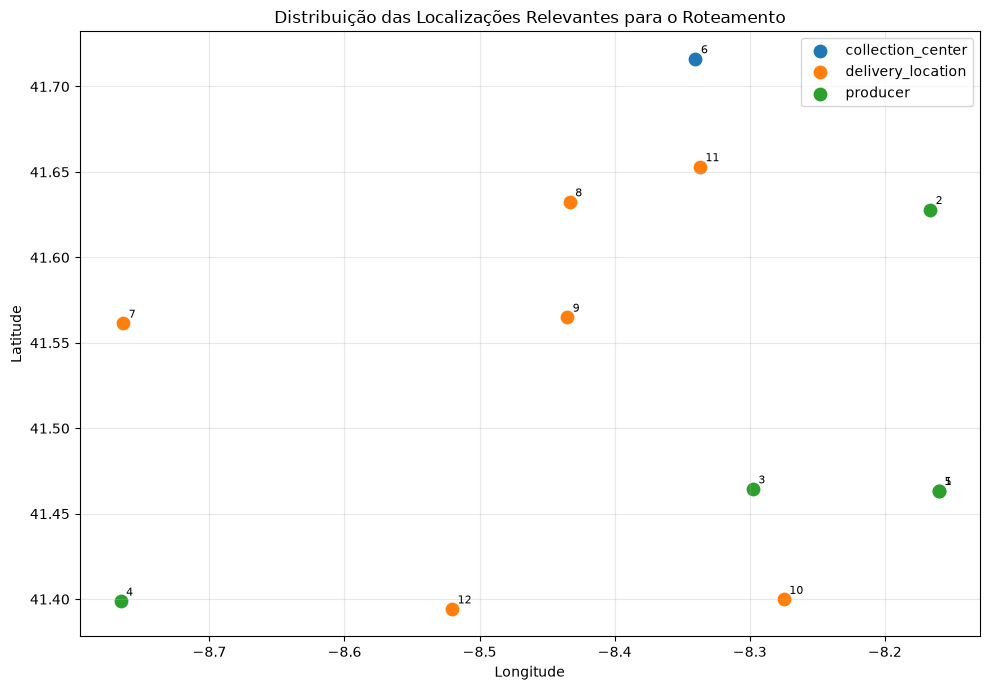

In [101]:
plt.figure(figsize=(10, 7))

for location_type, group in locations.groupby(
    "location_type"
):
    plt.scatter(
        group["longitude"],
        group["latitude"],
        label=location_type,
        s=80
    )

for _, row in locations.iterrows():
    plt.annotate(
        str(row["location_id"]),
        (
            row["longitude"],
            row["latitude"]
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(
    "Distribuição das Localizações Relevantes para o Roteamento"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A representação geográfica evidencia que os pontos utilizados pelo problema se encontram distribuídos por diferentes municípios.

Deste modo, a ordem de visita aos produtores e aos locais de entrega poderá ter um impacto significativo na distância e no tempo total das rotas.

### 7.1 Localizações com Coordenadas Coincidentes

São ainda procuradas localizações distintas que possuam exatamente as mesmas coordenadas.

Esta situação é relevante porque pode originar pares diferentes na matriz de distâncias com custo de deslocação igual a zero.

In [102]:
duplicate_coordinates = locations[
    locations.duplicated(
        subset=[
            "latitude",
            "longitude"
        ],
        keep=False
    )
].sort_values(
    [
        "latitude",
        "longitude"
    ]
)

display(
    duplicate_coordinates[
        [
            "location_id",
            "location_type",
            "ref_id",
            "name",
            "municipality",
            "latitude",
            "longitude"
        ]
    ]
)

,location_id,location_type,ref_id,name,municipality,latitude,longitude
0,1,producer,1,Hortas Valente,Fafe,41.463574,-8.15984
4,5,producer,5,Pomar Antunes,Fafe,41.463574,-8.15984


Foram identificados dois produtores distintos com exatamente as mesmas coordenadas geográficas: `Hortas Valente` e `Pomar Antunes`.

Consequentemente, é esperado que a matriz de distâncias contenha uma deslocação de custo zero entre estas duas localizações.

Este comportamento não deverá ser tratado como um erro, uma vez que resulta diretamente da informação geográfica fornecida.

## 8. Matriz de Distâncias e Tempos de Viagem

A tabela `distance_matrix` representa as ligações entre os diferentes pontos da rede.

Para cada par origem-destino são fornecidos:

- o identificador da origem;
- o tipo da origem;
- o identificador do destino;
- o tipo do destino;
- a distância em quilómetros;
- a duração estimada da viagem em minutos.

Esta informação será fundamental para calcular o custo das rotas e atualizar o tempo do veículo durante as deslocações.

### 8.1 Completude da Matriz

Com 12 localizações, uma matriz dirigida que contenha todas as deslocações entre pontos distintos deverá possuir:

\[
12 \times (12-1) = 132
\]

pares origem-destino.

As deslocações de uma localização para ela própria não são necessárias.

In [103]:
number_of_locations = len(locations)

expected_pairs = (
    number_of_locations
    *
    (number_of_locations - 1)
)

matrix_completeness = pd.DataFrame({
    "Indicador": [
        "Número de localizações",
        "Pares origem-destino esperados",
        "Pares existentes"
    ],
    "Valor": [
        number_of_locations,
        expected_pairs,
        len(distance_matrix)
    ]
})

display(matrix_completeness)

,Indicador,Valor
0,Número de localizações,12
1,Pares origem-destino esperados,132
2,Pares existentes,132


In [104]:
duplicate_pairs = (
    distance_matrix
    .duplicated(
        subset=[
            "origin_location_id",
            "destination_location_id"
        ]
    )
    .sum()
)

self_connections = (
    distance_matrix["origin_location_id"]
    ==
    distance_matrix["destination_location_id"]
).sum()

negative_distances = (
    distance_matrix["distance_km"] < 0
).sum()

negative_durations = (
    distance_matrix["duration_min"] < 0
).sum()

zero_distances = (
    distance_matrix["distance_km"] == 0
).sum()

matrix_validation = pd.DataFrame({
    "Verificação": [
        "Pares duplicados",
        "Ligações origem = destino",
        "Distâncias negativas",
        "Durações negativas",
        "Distâncias iguais a zero"
    ],
    "Número de casos": [
        duplicate_pairs,
        self_connections,
        negative_distances,
        negative_durations,
        zero_distances
    ]
})

display(matrix_validation)

,Verificação,Número de casos
0,Pares duplicados,0
1,Ligações origem = destino,0
2,Distâncias negativas,0
3,Durações negativas,0
4,Distâncias iguais a zero,2


In [105]:
zero_distance_pairs = distance_matrix[
    distance_matrix["distance_km"] == 0
]

display(zero_distance_pairs)

,origin_location_id,origin_type,destination_location_id,destination_type,distance_km,duration_min
3,1,producer,5,producer,0.0,0.0
44,5,producer,1,producer,0.0,0.0


A matriz não contém pares origem-destino duplicados, ligações de uma localização para ela própria, distâncias negativas ou durações negativas.

Existem duas deslocações com distância e duração iguais a zero, correspondentes aos dois sentidos entre as localizações 1 e 5.

Como verificado anteriormente, estas localizações correspondem a produtores diferentes com as mesmas coordenadas geográficas. Os valores nulos são, portanto, coerentes com os dados fornecidos.

### 8.2 Consistência dos Tipos de Localização

A matriz contém também os campos `origin_type` e `destination_type`.

É verificado se estes tipos correspondem efetivamente aos tipos definidos na tabela `locations`.

In [106]:
location_type_map = (
    locations
    .set_index("location_id")
    ["location_type"]
)

origin_type_mismatches = (
    distance_matrix["origin_type"]
    !=
    distance_matrix[
        "origin_location_id"
    ].map(location_type_map)
).sum()

destination_type_mismatches = (
    distance_matrix["destination_type"]
    !=
    distance_matrix[
        "destination_location_id"
    ].map(location_type_map)
).sum()

type_validation = pd.DataFrame({
    "Verificação": [
        "Tipos de origem inconsistentes",
        "Tipos de destino inconsistentes"
    ],
    "Número de casos": [
        origin_type_mismatches,
        destination_type_mismatches
    ]
})

display(type_validation)

,Verificação,Número de casos
0,Tipos de origem inconsistentes,0
1,Tipos de destino inconsistentes,0


Não foram encontradas inconsistências entre os tipos de localização presentes na matriz e os tipos definidos na tabela `locations`.

A informação da matriz encontra-se, portanto, consistente com a estrutura da rede.

### 8.3 Simetria da Matriz

É analisado se a distância e a duração entre duas localizações são iguais nos dois sentidos.

Embora a matriz desta instância possa ser simétrica, a futura implementação não deverá depender obrigatoriamente dessa propriedade, uma vez que redes rodoviárias reais podem apresentar custos diferentes consoante o sentido da deslocação.

In [107]:
reverse_matrix = (
    distance_matrix
    .rename(
        columns={
            "origin_location_id":
                "destination_location_id",

            "destination_location_id":
                "origin_location_id",

            "distance_km":
                "reverse_distance_km",

            "duration_min":
                "reverse_duration_min"
        }
    )
)

symmetry_check = (
    distance_matrix
    .merge(
        reverse_matrix[
            [
                "origin_location_id",
                "destination_location_id",
                "reverse_distance_km",
                "reverse_duration_min"
            ]
        ],
        on=[
            "origin_location_id",
            "destination_location_id"
        ],
        how="left"
    )
)

symmetry_check["distance_difference"] = (
    symmetry_check["distance_km"]
    -
    symmetry_check["reverse_distance_km"]
).abs()

symmetry_check["duration_difference"] = (
    symmetry_check["duration_min"]
    -
    symmetry_check["reverse_duration_min"]
).abs()

print(
    "Diferença máxima de distância:",
    symmetry_check["distance_difference"].max()
)

print(
    "Diferença máxima de duração:",
    symmetry_check["duration_difference"].max()
)

Diferença máxima de distância: 0.0
Diferença máxima de duração: 0.0


A matriz é totalmente simétrica na instância `tiny`.

Assim, a distância e a duração de uma deslocação de A para B são iguais aos valores da deslocação de B para A.

Apesar deste resultado, a implementação futura deverá preferencialmente consultar sempre a matriz utilizando explicitamente o par origem-destino, evitando assumir simetria como uma propriedade geral do problema.

In [108]:
display(
    distance_matrix[
        [
            "distance_km",
            "duration_min"
        ]
    ].describe()
)

,distance_km,duration_min
count,132.000000,132.000000
mean,35.724848,47.633333
std,16.799530,22.396819
min,0.000000,0.000000
25%,23.780000,31.700000
50%,35.280000,47.050000
75%,48.000000,64.000000
max,72.840000,97.100000


A distância média entre os pontos da rede é aproximadamente **35,72 km**, enquanto a duração média estimada é aproximadamente **47,63 minutos**.

A maior distância existente é **72,84 km**, associada a uma duração máxima de aproximadamente **97,1 minutos**.

Estes valores mostram que as deslocações podem representar uma parte significativa das janelas temporais existentes, reforçando a importância de considerar simultaneamente distância, duração e horários durante a construção das rotas.

### 8.4 Relação entre Distância e Tempo

O guia do projeto indica que a duração da viagem foi obtida sinteticamente a partir da distância utilizando uma velocidade rodoviária média de aproximadamente 45 km/h.

Esta relação é validada nos dados.

In [109]:
expected_duration_45 = (
    distance_matrix["distance_km"]
    /
    45
    *
    60
)

duration_difference = (
    distance_matrix["duration_min"]
    -
    expected_duration_45
).abs()

print(
    "Diferença média:",
    round(
        duration_difference.mean(),
        3
    ),
    "min"
)

print(
    "Diferença máxima:",
    round(
        duration_difference.max(),
        3
    ),
    "min"
)

Diferença média: 0.021 min
Diferença máxima: 0.053 min


As durações registadas na matriz são praticamente iguais às durações obtidas através de uma velocidade média de 45 km/h, apresentando apenas pequenas diferenças de arredondamento.

Desta forma, `duration_min` pode ser utilizada diretamente para atualizar o tempo durante uma deslocação, sem necessidade de recalcular a duração a partir da distância.

### 8.5 Observação sobre `avg_speed_kmh`

A tabela `vehicles` contém também o atributo `avg_speed_kmh`.

Os dois veículos apresentam velocidades médias próprias superiores à velocidade aproximada utilizada na construção da matriz.

No entanto, como `distance_matrix` fornece diretamente a duração prevista de cada deslocação e o guia apresenta esta matriz como a informação temporal entre localizações, nesta fase será utilizada diretamente a coluna `duration_min`.

O campo `avg_speed_kmh` será mantido como atributo do veículo, mas não será utilizado para recalcular os tempos enquanto não existir uma indicação explícita nesse sentido.

Esta decisão evita utilizar simultaneamente dois critérios diferentes para calcular a duração da mesma deslocação.

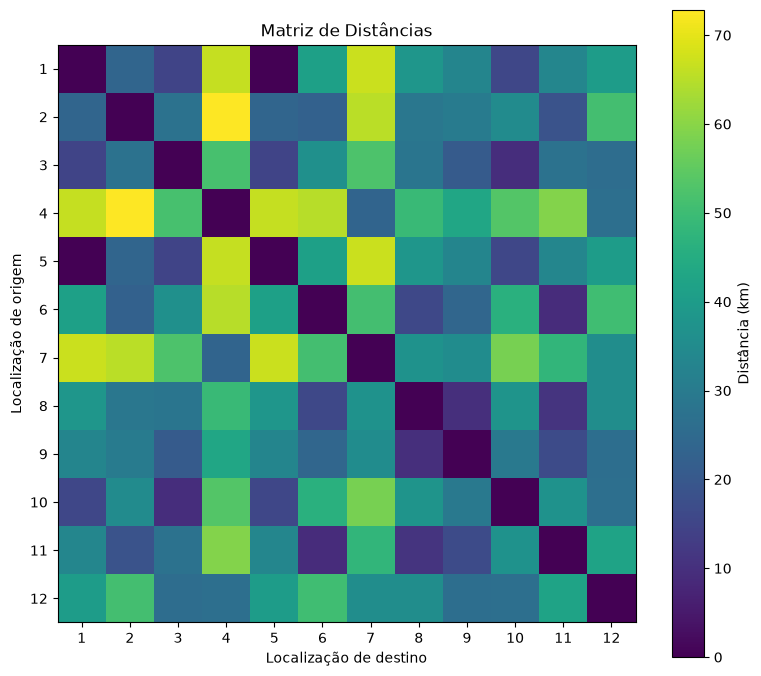

In [110]:
distance_table = (
    distance_matrix
    .pivot(
        index="origin_location_id",
        columns="destination_location_id",
        values="distance_km"
    )
)

location_ids = sorted(
    locations["location_id"].unique()
)

distance_table = (
    distance_table
    .reindex(
        index=location_ids,
        columns=location_ids
    )
)

# A diagonal não existe na matriz original.
# É preenchida com zero apenas para visualização.
distance_plot = distance_table.fillna(0)

plt.figure(figsize=(8, 7))

image = plt.imshow(distance_plot)

plt.title("Matriz de Distâncias")
plt.xlabel("Localização de destino")
plt.ylabel("Localização de origem")

plt.xticks(
    range(len(location_ids)),
    location_ids
)

plt.yticks(
    range(len(location_ids)),
    location_ids
)

plt.colorbar(
    image,
    label="Distância (km)"
)

plt.tight_layout()
plt.show()

### 8.6 Síntese da Matriz de Distâncias

A análise permite concluir que a matriz apresenta as propriedades necessárias para suportar os futuros algoritmos:

- contém todos os 132 pares origem-destino esperados;
- não contém pares duplicados;
- não contém distâncias ou durações negativas;
- os tipos de origem e destino estão consistentes com a tabela `locations`;
- os dois valores de distância zero são explicados por coordenadas coincidentes;
- é simétrica na instância `tiny`;
- os tempos de viagem são coerentes com a aproximação de 45 km/h descrita no projeto.

A matriz poderá, portanto, ser utilizada como fonte de custo e duração para as deslocações do agente.

## 9. Verificações Orientadas para a Modelação

Antes da implementação dos algoritmos, são realizadas algumas verificações adicionais destinadas a perceber se existem pedidos individualmente impossíveis.

Estas verificações não procuram encontrar uma solução global para o problema. Servem apenas para identificar situações que tornariam um pedido inviável mesmo antes da combinação com outros pedidos.

In [111]:
producer_routing_locations = (
    locations[
        locations["location_type"]
        ==
        "producer"
    ][
        [
            "ref_id",
            "location_id"
        ]
    ]
    .rename(
        columns={
            "ref_id":
                "producer_id",

            "location_id":
                "pickup_location_id"
        }
    )
)

delivery_routing_locations = (
    locations[
        locations["location_type"]
        ==
        "delivery_location"
    ][
        [
            "ref_id",
            "location_id"
        ]
    ]
    .rename(
        columns={
            "ref_id":
                "delivery_location_id",

            "location_id":
                "dropoff_location_id"
        }
    )
)

In [112]:
request_check = (
    order_items
    .merge(
        products[
            [
                "product_id",
                "producer_id"
            ]
        ],
        on="product_id",
        how="left"
    )
    .merge(
        orders[
            [
                "order_id",
                "delivery_location_id"
            ]
        ],
        on="order_id",
        how="left"
    )
    .merge(
        producer_routing_locations,
        on="producer_id",
        how="left"
    )
    .merge(
        delivery_routing_locations,
        on="delivery_location_id",
        how="left"
    )
)

Cada item possui agora explicitamente:

- o produtor associado;
- a localização de recolha;
- o local de entrega;
- a localização de entrega na rede.

Esta estrutura aproxima-se da informação que será posteriormente necessária para representar um pedido no agente, sem ainda implementar qualquer algoritmo de pesquisa.

In [113]:
request_check = (
    request_check
    .merge(
        distance_matrix[
            [
                "origin_location_id",
                "destination_location_id",
                "duration_min"
            ]
        ],
        left_on=[
            "pickup_location_id",
            "dropoff_location_id"
        ],
        right_on=[
            "origin_location_id",
            "destination_location_id"
        ],
        how="left"
    )
)

### 9.1 Verificação de Viabilidade Temporal Individual

É realizado um teste simplificado para cada item.

Considera-se o cenário mais favorável em que:

1. a recolha ocorre exatamente no início da janela de disponibilidade;
2. o veículo segue diretamente do produtor para o local de entrega;
3. não são realizadas outras paragens pelo caminho.

Calcula-se então o instante mais cedo em que seria possível chegar ao destino.

Se mesmo neste cenário o veículo chegasse depois de `delivery_end`, o pedido seria individualmente inviável.

In [114]:
request_check["earliest_direct_arrival"] = (
    request_check["availability_start"]
    +
    pd.to_timedelta(
        request_check["duration_min"],
        unit="m"
    )
)

request_check["individually_feasible"] = (
    request_check["earliest_direct_arrival"]
    <=
    request_check["delivery_end"]
)

infeasible_requests = request_check[
    ~request_check["individually_feasible"]
]

print(
    "Itens analisados:",
    len(request_check)
)

print(
    "Itens sem viabilidade temporal direta:",
    len(infeasible_requests)
)

Itens analisados: 23
Itens sem viabilidade temporal direta: 0


In [115]:
display(
    request_check[
        [
            "order_item_id",
            "order_id",
            "producer_id",
            "pickup_location_id",
            "dropoff_location_id",
            "duration_min",
            "availability_start",
            "delivery_start",
            "delivery_end",
            "earliest_direct_arrival",
            "individually_feasible"
        ]
    ].head(10)
)

,order_item_id,order_id,producer_id,pickup_location_id,dropoff_location_id,duration_min,availability_start,delivery_start,delivery_end,earliest_direct_arrival,individually_feasible
0,1,1,1,1,12,53.8,2026-10-13 08:00:00,2026-10-13 13:00:00,2026-10-13 17:00:00,2026-10-13 08:53:48,True
1,2,1,2,2,12,68.1,2026-10-17 12:45:00,2026-10-18 13:45:00,2026-10-18 17:45:00,2026-10-17 13:53:06,True
2,3,2,2,2,12,68.1,2026-10-07 09:00:00,2026-10-07 12:00:00,2026-10-07 14:00:00,2026-10-07 10:08:06,True
3,4,2,2,2,12,68.1,2026-10-09 07:00:00,2026-10-09 12:00:00,2026-10-09 16:00:00,2026-10-09 08:08:06,True
4,5,3,4,4,10,71.0,2026-10-10 10:00:00,2026-10-10 15:00:00,2026-10-10 19:00:00,2026-10-10 11:11:00,True
5,6,3,4,4,10,71.0,2026-10-20 10:30:00,2026-10-20 12:30:00,2026-10-20 15:30:00,2026-10-20 11:41:00,True
6,7,3,4,4,10,71.0,2026-10-19 08:30:00,2026-10-19 11:30:00,2026-10-19 12:30:00,2026-10-19 09:41:00,True
7,8,3,4,4,10,71.0,2026-10-12 12:45:00,2026-10-12 13:45:00,2026-10-12 14:45:00,2026-10-12 13:56:00,True
8,9,4,3,3,8,37.8,2026-10-12 09:00:00,2026-10-12 14:00:00,2026-10-12 18:00:00,2026-10-12 09:37:48,True
9,10,4,4,4,8,65.8,2026-10-19 07:30:00,2026-10-19 08:30:00,2026-10-19 12:30:00,2026-10-19 08:35:48,True


In [116]:
request_check["arrives_before_delivery_window"] = (
    request_check["earliest_direct_arrival"]
    <
    request_check["delivery_start"]
)

early_arrivals = (
    request_check[
        "arrives_before_delivery_window"
    ].sum()
)

print(
    "Itens cuja chegada direta mais cedo ocorre "
    "antes do início da janela de entrega:",
    early_arrivals
)

Itens cuja chegada direta mais cedo ocorre antes do início da janela de entrega: 21


Todos os 23 itens apresentam viabilidade temporal individual neste teste simplificado: partindo no início da respetiva janela de recolha e seguindo diretamente para o destino, é possível chegar antes do fim da janela de entrega.

Em 21 dos 23 casos, essa chegada mais cedo ocorreria antes do início da janela de entrega.

Esta situação não representa necessariamente um problema. Num modelo que permita espera, o veículo poderá aguardar até ao início da janela antes de realizar a entrega.

A utilização de tempos de espera deverá ser explicitamente definida durante a fase de modelação.

É importante salientar que esta verificação **não demonstra a existência de uma solução global**. Ao combinar vários pedidos na mesma rota surgem deslocações adicionais, interações entre janelas temporais e alterações de carga que não são consideradas neste teste.

In [117]:
request_check["slack_to_delivery_end_min"] = (
    request_check["delivery_end"]
    -
    request_check["earliest_direct_arrival"]
).dt.total_seconds() / 60

display(
    request_check[
        ["slack_to_delivery_end_min"]
    ].describe()
)

,slack_to_delivery_end_min
count,23.000000
mean,662.786957
std,673.658147
min,49.000000
25%,203.200000
50%,323.200000
75%,1086.200000
max,1928.900000


Mesmo no pedido individual com menor margem, a chegada direta calculada ocorre aproximadamente **49 minutos antes do fim da janela de entrega**.

Existe, portanto, alguma margem temporal em todos os pedidos considerados isoladamente.

Mais uma vez, esta margem poderá diminuir significativamente quando vários pedidos forem combinados numa mesma rota.

### 9.2 Implicações para a Modelação

A análise exploratória permite antecipar algumas características importantes da futura representação do problema.

**Tempo**

O estado de cada veículo deverá incluir um instante atual, uma vez que cada deslocação altera a possibilidade de satisfazer as janelas seguintes.

**Carga**

A carga deverá ser atualizada dinamicamente. Uma recolha aumenta a carga transportada e uma entrega liberta a capacidade correspondente.

**Precedência**

Cada item apenas poderá ser entregue depois de ter sido recolhido no respetivo produtor.

**Espera**

Poderá ser necessário permitir que um veículo chegue antecipadamente a uma localização e aguarde pelo início da respetiva janela temporal.

**Custos**

A distância poderá ser utilizada como principal medida de custo da rota, enquanto `duration_min` será utilizada para atualizar o tempo e verificar a viabilidade temporal.

**Matriz de deslocações**

Mesmo sendo simétrica na instância `tiny`, a implementação deverá consultar explicitamente o custo do par origem-destino e evitar assumir essa propriedade de forma geral.

Estas observações serão utilizadas posteriormente durante a definição das estruturas de estado e das funções de custo e validação.

## 10. Conclusão da Análise Exploratória

A análise exploratória permitiu compreender a estrutura da instância `tiny`, validar a qualidade dos dados e identificar os aspetos com maior impacto na futura modelação do agente de roteamento.

### Qualidade e integridade dos dados

Não foram encontrados valores em falta nem linhas integralmente duplicadas.

As principais chaves primárias são únicas e não apresentam valores em falta. Também não foram identificadas referências inválidas nas relações fundamentais entre produtores, produtos, clientes, encomendas, itens, veículos, centros e localidades.

A tabela `locations` apresenta igualmente referências consistentes com as entidades que representa.

### Entidades e procura

A instância contém 5 produtores, 23 produtos, 8 clientes, 10 encomendas e 23 itens de encomenda.

Uma encomenda possui, em média, 2,3 itens, podendo incluir produtos provenientes de diferentes produtores.

A procura não se encontra uniformemente distribuída pelos produtores, tanto em número de itens como em peso total a recolher.

### Janelas temporais

Não foram encontradas janelas de recolha ou entrega com início posterior ao respetivo fim.

As janelas de recolha apresentam uma duração média de aproximadamente **3,87 horas**, enquanto as janelas de entrega apresentam uma duração média de aproximadamente **2,78 horas**, indicando que as entregas tendem a possuir intervalos mais restritos.

Foram ainda identificados 6 itens cuja recolha e entrega se encontram associadas a dias diferentes.

Foi observada uma particularidade na relação entre `order_datetime` e as janelas temporais. Como existem janelas anteriores ao instante registado para a própria encomenda, `order_datetime` será tratado, nesta fase, como informação descritiva, enquanto as janelas de disponibilidade e entrega serão utilizadas como restrições operacionais.

### Peso e capacidade

Os 23 itens representam aproximadamente **248,96 kg**.

A encomenda mais pesada possui aproximadamente **49,90 kg**, enquanto o veículo com menor capacidade suporta **1009,8 kg**.

Assim, a capacidade dos veículos não aparenta ser a principal restrição da instância `tiny`. Ainda assim, deverá ser controlada dinamicamente durante as rotas, uma vez que um veículo poderá transportar vários pedidos em simultâneo.

### Rede geográfica

O problema utiliza 12 localizações: 5 produtores, 1 centro de recolha e 6 locais de entrega.

Foram identificados dois produtores distintos com as mesmas coordenadas geográficas, explicando a existência de deslocações de custo zero entre essas localizações.

### Distâncias e tempos

A matriz contém os **132 pares origem-destino esperados**, sem duplicados ou valores negativos.

A matriz é simétrica nesta instância e apresenta uma distância média de aproximadamente **35,72 km** e um tempo médio de viagem de aproximadamente **47,63 minutos**.

Os valores de duração são consistentes com a aproximação de 45 km/h indicada na descrição do dataset.

### Viabilidade individual

Todos os itens são temporalmente viáveis quando analisados isoladamente num cenário direto entre produtor e local de entrega.

Este resultado não garante que todos possam ser combinados numa solução global, mas indica que não existe nenhum pedido individual obviamente impossível devido apenas à sua janela temporal e ao tempo mínimo de deslocação direta.



